##  Generation of Matplotlib figures from validation data 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Classic journal style
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("paper", font_scale=1.2)

# ------------------------------------------------------------------
# Load data
# ------------------------------------------------------------------
df = pd.read_csv("validation_data.csv")

# Ensure consistent material labels
df["Material"] = df["Material"].replace({"Wrought 6xxx": "Wrought",
                                         "Cast LM27": "Cast"})

# NSGA-II / MOGPR targets
targets = {
    "E1": {"H": 1000, "AR": 0.40, "D": 40.0},
    "E2": {"H":  440, "AR": 0.21, "D": 30.0},
    "E3": {"H": 1200, "AR": 0.46, "D": 35.0},
    "E4": {"H": 1600, "AR": 0.50, "D": 20.0},
}

exps = ["E1", "E2", "E3", "E4"]
materials = ["Wrought", "Cast"]
responses = ["H", "AR", "D"]

# Compute mean, std, CV by Material–Exp–Response
agg = df.groupby(["Material", "Exp"]).agg(["mean", "std"]).reset_index()
# Flatten columns: ("H","mean") -> "H_mean"
agg.columns = ["Material", "Exp"] + [
    f"{c[0]}_{c[1]}" for c in agg.columns[2:]
]

# Helper functions
def get_mean(material, exp, resp):
    row = agg[(agg["Material"] == material) & (agg["Exp"] == exp)]
    return row[f"{resp}_mean"].values[0]

def get_std(material, exp, resp):
    row = agg[(agg["Material"] == material) & (agg["Exp"] == exp)]
    return row[f"{resp}_std"].values[0]

def get_target(exp, resp):
    return targets[exp][resp]

# Compute CV (%) per Material–Exp–Response (for later heatmap)
cv_records = []
for mat in materials:
    for exp in exps:
        for resp in responses:
            mu = get_mean(mat, exp, resp)
            sd = get_std(mat, exp, resp)
            cv = 100 * sd / mu if mu != 0 else np.nan
            cv_records.append(
                {"Material": mat, "Exp": exp, "Response": resp, "CV": cv}
            )
df_cv = pd.DataFrame(cv_records)

# Compute MAPE (%) per Material–Response (using Exp targets)
mape_records = []
for mat in materials:
    for resp in responses:
        errs = []
        for exp in exps:
            mu = get_mean(mat, exp, resp)
            tgt = get_target(exp, resp)
            errs.append(abs(mu - tgt) / tgt * 100)
        mape_records.append(
            {"Material": mat, "Response": resp, "MAPE": np.mean(errs)}
        )
df_mape = pd.DataFrame(mape_records)

##  Figure 1 – 3‑panel grouped bar (Height, AR, Dilution)


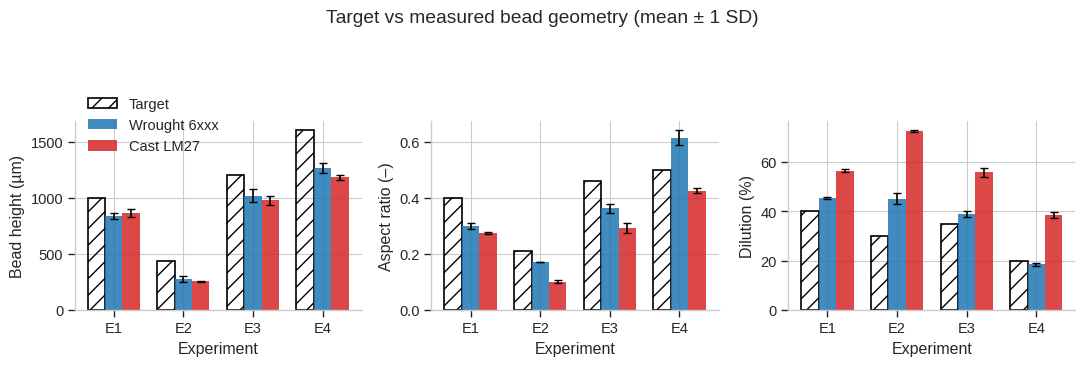

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), sharex=True)

metric_info = [
    ("H",  "Bead height (µm)"),
    ("AR", "Aspect ratio (–)"),
    ("D",  "Dilution (%)"),
]

colors = {
    "Target":  "black",
    "Wrought": "#1f77b4",
    "Cast":    "#d62728",
}

x = np.arange(len(exps))
width = 0.25  # bar width per group

for ax, (resp, ylabel) in zip(axes, metric_info):
    # targets
    t_vals = [get_target(e, resp) for e in exps]
    ax.bar(x - width, t_vals, width, label="Target", color="none",
           edgecolor=colors["Target"], linewidth=1.2, hatch="//")

    # wrought
    w_means = [get_mean("Wrought", e, resp) for e in exps]
    w_stds  = [get_std("Wrought", e, resp) for e in exps]
    ax.bar(x, w_means, width, yerr=w_stds, label="Wrought 6xxx",
           color=colors["Wrought"], alpha=0.85, capsize=3)

    # cast
    c_means = [get_mean("Cast", e, resp) for e in exps]
    c_stds  = [get_std("Cast", e, resp) for e in exps]
    ax.bar(x + width, c_means, width, yerr=c_stds, label="Cast LM27",
           color=colors["Cast"], alpha=0.85, capsize=3)

    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    ax.set_xticklabels(exps)
    ax.set_xlabel("Experiment")
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)

axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 1.2))
fig.suptitle("Target vs measured bead geometry (mean ± 1 SD)", y=1.04)
fig.tight_layout()
plt.savefig("fig1_bar_all.png", dpi=600, bbox_inches="tight")
plt.show()

### Figure 2 – 3‑panel 1:1 scatter (Predicted vs Measured)

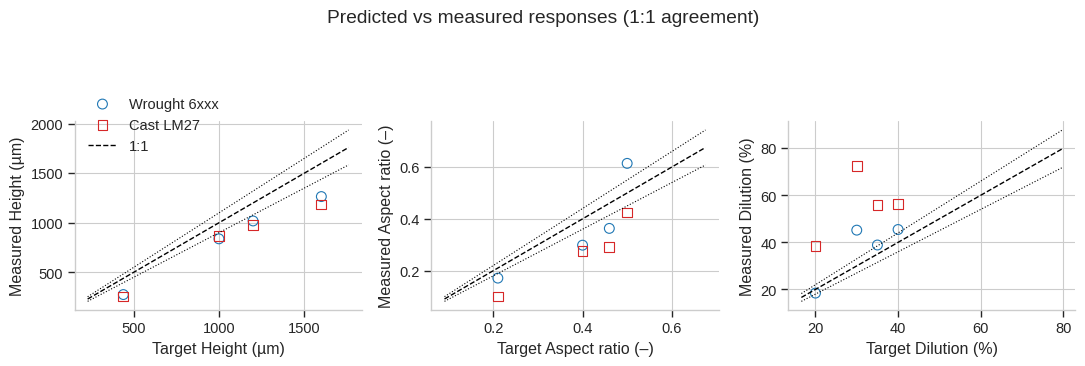

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))

metric_info = [
    ("H",  "Height (µm)"),
    ("AR", "Aspect ratio (–)"),
    ("D",  "Dilution (%)"),
]

for ax, (resp, label) in zip(axes, metric_info):
    xs_w, ys_w = [], []
    xs_c, ys_c = [], []

    for exp in exps:
        tgt = get_target(exp, resp)
        xs_w.append(tgt)
        ys_w.append(get_mean("Wrought", exp, resp))
        xs_c.append(tgt)
        ys_c.append(get_mean("Cast", exp, resp))

    # data points
    ax.scatter(xs_w, ys_w, marker="o", s=50,
               facecolors="none", edgecolors=colors["Wrought"],
               label="Wrought 6xxx")
    ax.scatter(xs_c, ys_c, marker="s", s=50,
               facecolors="none", edgecolors=colors["Cast"],
               label="Cast LM27")

    # 1:1 line and ±10%
    all_vals = xs_w + ys_w + xs_c + ys_c
    lo = min(all_vals) * 0.9
    hi = max(all_vals) * 1.1
    grid = np.linspace(lo, hi, 100)
    ax.plot(grid, grid, "k--", linewidth=1, label="1:1")
    ax.plot(grid, 1.1 * grid, "k:", linewidth=0.8)
    ax.plot(grid, 0.9 * grid, "k:", linewidth=0.8)

    ax.set_xlabel(f"Target {label}")
    ax.set_ylabel(f"Measured {label}")
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)

axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 1.2))
fig.suptitle("Predicted vs measured responses (1:1 agreement)", y=1.04)
fig.tight_layout()
plt.savefig("fig2_scatter_all.png", dpi=600, bbox_inches="tight")
plt.show()

## Figure 3 – 3‑panel Bland‑Altman

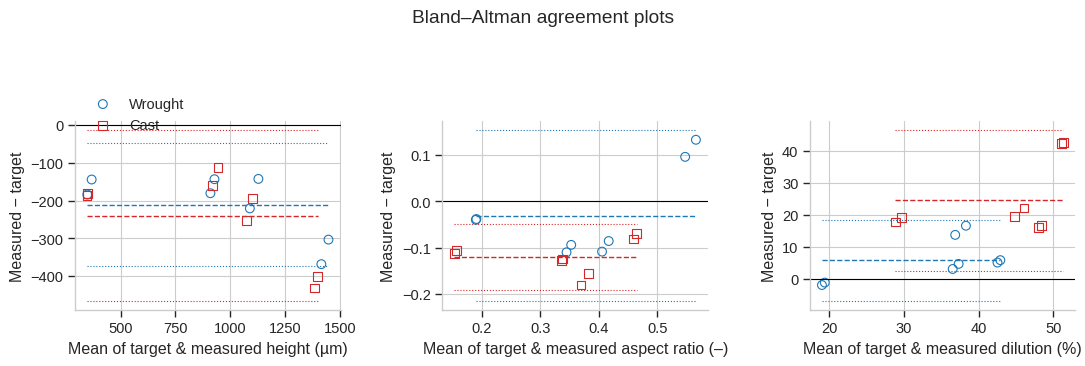

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))

for ax, (resp, label) in zip(axes, metric_info):
    for mat, mcol, marker in [("Wrought", colors["Wrought"], "o"),
                              ("Cast",    colors["Cast"],    "s")]:
        diffs = []
        means = []
        # use each individual clad (not just mean) for BA
        sub = df[df["Material"] == mat]
        for _, row in sub.iterrows():
            exp = row["Exp"]
            tgt = get_target(exp, resp)
            meas = row[resp]
            diffs.append(meas - tgt)
            means.append(0.5 * (meas + tgt))

        diffs = np.array(diffs)
        means = np.array(means)
        bias = np.mean(diffs)
        sd   = np.std(diffs, ddof=1)
        loa_upper = bias + 1.96 * sd
        loa_lower = bias - 1.96 * sd

        ax.scatter(means, diffs, marker=marker, s=40,
                   facecolors="none", edgecolors=mcol, label=mat)

        x_min, x_max = means.min(), means.max()
        ax.hlines(bias, x_min, x_max, colors=mcol, linestyles="--", linewidth=1)
        ax.hlines([loa_lower, loa_upper], x_min, x_max,
                  colors=mcol, linestyles=":", linewidth=0.8)

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xlabel(f"Mean of target & measured {label.lower()}")
    ax.set_ylabel("Measured − target")
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)

axes[0].legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 1.2))
fig.suptitle("Bland–Altman agreement plots", y=1.04)
fig.tight_layout()
plt.savefig("fig3_bland_altman.png", dpi=600, bbox_inches="tight")
plt.show()

### Figure 4 – MAPE radar (Wrought vs Cast)

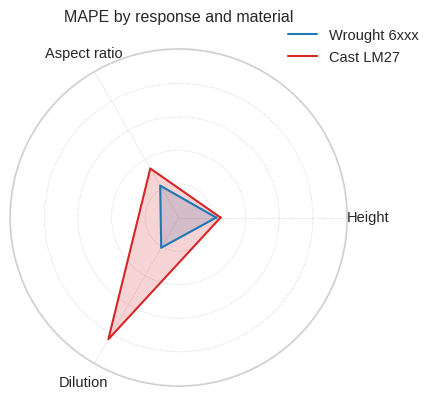

In [5]:
# Prepare MAPE values in fixed order
order = ["H", "AR", "D"]
labels = ["Height", "Aspect ratio", "Dilution"]

mape_w = [df_mape[(df_mape["Material"] == "Wrought") &
                  (df_mape["Response"] == r)]["MAPE"].values[0] for r in order]
mape_c = [df_mape[(df_mape["Material"] == "Cast") &
                  (df_mape["Response"] == r)]["MAPE"].values[0] for r in order]

# close the loop
mape_w += [mape_w[0]]
mape_c += [mape_c[0]]
theta = np.linspace(0, 2 * np.pi, len(order) + 1)

fig = plt.figure(figsize=(4.5, 4.5))
ax = fig.add_subplot(111, polar=True)

ax.plot(theta, mape_w, color=colors["Wrought"], linewidth=1.5, label="Wrought 6xxx")
ax.fill(theta, mape_w, color=colors["Wrought"], alpha=0.2)
ax.plot(theta, mape_c, color=colors["Cast"], linewidth=1.5, label="Cast LM27")
ax.fill(theta, mape_c, color=colors["Cast"], alpha=0.2)

ax.set_xticks(theta[:-1])
ax.set_xticklabels(labels)
ax.set_ylim(0, max(max(mape_w), max(mape_c)) * 1.2)
ax.set_yticklabels([])

ax.grid(True, linestyle=":", linewidth=0.6)
ax.set_title("MAPE by response and material", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1), frameon=False)
plt.tight_layout()
plt.savefig("fig4_mape_radar.png", dpi=600, bbox_inches="tight")
plt.show()

### 7. Figure 5 – CV heatmap (repeatability)


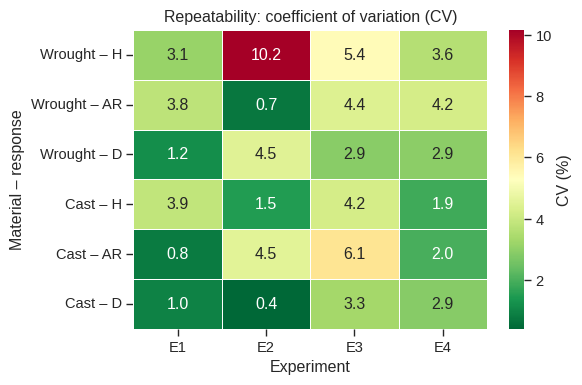

In [6]:
# Pivot: rows = Material–Response, cols = Exp, values = CV
df_cv["Row"] = df_cv["Material"] + " – " + df_cv["Response"]
heat = df_cv.pivot(index="Row", columns="Exp", values="CV").loc[
    [f"{m} – {r}" for m in materials for r in responses]
]

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(
    heat, annot=True, fmt=".1f", cmap="RdYlGn_r",
    cbar_kws={"label": "CV (%)"}, ax=ax, linewidths=0.5, linecolor="white"
)
ax.set_xlabel("Experiment")
ax.set_ylabel("Material – response")
ax.set_title("Repeatability: coefficient of variation (CV)")
plt.tight_layout()
plt.savefig("fig5_cv_heatmap.png", dpi=600, bbox_inches="tight")
plt.show()